<a href="https://colab.research.google.com/github/vertgram/Pius_Olasupo/blob/v0%2Fvertgram-6008c7b3/SUPERVISED_FRAMING_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 3 — Supervised Framing
**CAMLDS Machine Learning Class · ML 1/8**

---

**Dataset:** Olist Brazilian E-commerce (Kaggle)
**Session time:** 2 hours
**Input:** `orders_full` and the `is_late` target, both built in Session 2
**New table:** `olist_order_reviews_dataset.csv`, introduced later in the Challenge Block

**By the end of this lab you will be able to:**
1. Explain why a supervised learning project needs a train set, a validation set, and a test set, and state what each one is for.
2. Build a baseline model (majority class for classification, mean or median for regression) and explain why every project needs one.
3. Spot data leakage in a feature set and explain why it makes a result invalid.
4. Explain the bias and variance tradeoff in plain terms and read the signature of each from train and validation error.

---

> **Reference:** StatQuest, "Machine Learning Fundamentals" playlist (Josh Starmer, YouTube)

## Block 0 — Environment Setup

Run this cell first. It imports pandas, numpy, and the scikit-learn tools we use today: `train_test_split` for splitting data, and scoring functions for measuring baselines.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['figure.dpi'] = 100

pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', '{:.2f}'.format)

print(f'pandas {pd.__version__}  |  scikit-learn {sklearn.__version__}  |  matplotlib {plt.matplotlib.__version__}')
print('Setup complete.')

pandas 2.2.3  |  scikit-learn 1.6.1  |  matplotlib 3.10.0
Setup complete.


---

## Block 1 — Rebuild orders_full and the is_late Target

Session 3 starts from the table you built across the first two sessions. Rather than re-teach the merges, we rebuild `orders_full` in one block, then rebuild `is_late`, the target you created in the Session 2 Challenge Block.

The fifth file, the reviews table, is new. It is not read into a DataFrame until the Challenge Block.

| CSV | What it contains |
|-----|------------------|
| `olist_orders_dataset.csv` | one row per order |
| `olist_order_items_dataset.csv` | one row per item |
| `olist_customers_dataset.csv` | customer location |
| `olist_order_payments_dataset.csv` | one row per payment attempt |
| `olist_order_reviews_dataset.csv` | one row per review, used only in the Challenge Block |

In [ ]:
# ── Download from Drive ──
import subprocess

FILES = {
    'olist_orders_dataset.csv'                        : '1tgJCWAoBs5KMRZvsB5QHvM_i83VWXMfx',
    'olist_order_items_dataset.csv'                   : '1kc7bVPVTLmHLOhJaIJV_hIJg1_q97UII',
    'olist_customers_dataset.csv'                     : '1_J9Q1vF36PkTYP61WAzXnHl9X3ul7Zhm',
    'olist_order_payments_dataset.csv'                : '1eMV4Z5iJ3MYvLmKdYCpKPnc34jRSm006',
    'olist_order_reviews_dataset.csv'                 : '1jhRNtnI-nEPNpnyDyBmbk2kkGbuOjFg9',
}

for fname, gid in FILES.items():
    url = f'https://drive.google.com/uc?id={gid}'
    subprocess.run(['gdown', url, '-O', fname], check=True)
    print(f'Downloaded {fname}')

Downloaded olist_orders_dataset.csv
Downloaded olist_order_items_dataset.csv
Downloaded olist_customers_dataset.csv
Downloaded olist_order_payments_dataset.csv
Downloaded olist_order_reviews_dataset.csv


In [ ]:
# Rebuild the Session 1 and Session 2 table
orders    = pd.read_csv('olist_orders_dataset.csv')
items     = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
payments  = pd.read_csv('olist_order_payments_dataset.csv')

# 1. Cast timestamps (Session 1, Block 4)
timestamp_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in timestamp_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

orders_clean = orders.dropna(subset=['order_purchase_timestamp']).copy()

# 2. Per-order item summary (Session 1, Block 7)
items['freight_value'] = items['freight_value'].fillna(0)
items['total_cost']    = items['price'] + items['freight_value']
order_summary = (
    items.groupby('order_id')
    .agg(item_count=('order_item_id', 'count'),
         total_price=('price', 'sum'),
         total_freight=('freight_value', 'sum'),
         total_cost=('total_cost', 'sum'))
    .reset_index()
)

# 3. Per-order payment summary (Session 1, Challenge Block)
payments_per_order = (
    payments.groupby('order_id')
    .agg(dominant_payment_type=('payment_type', lambda x: x.value_counts().index[0]),
         total_payment_value=('payment_value', 'sum'),
         max_installments=('payment_installments', 'max'))
    .reset_index()
)

# 4. Merge into one flat table (Session 1, Block 9)
orders_full = (
    orders_clean
    .merge(order_summary, on='order_id', how='left')
    .merge(customers[['customer_id', 'customer_state', 'customer_city']],
           on='customer_id', how='left')
    .merge(payments_per_order, on='order_id', how='left')
)

# 5. Delivery time in days (Session 2, Block 1)
orders_full['delivery_days'] = (
    (orders_full['order_delivered_customer_date'] - orders_full['order_purchase_timestamp'])
    .dt.days
)

print(f'orders_full: {orders_full.shape[0]:,} rows x {orders_full.shape[1]} columns')

# 6. Rebuild is_late (Session 2, Challenge Block reveal). is_late only makes sense
#    for orders that were actually delivered, so this is today's working table.
delivered = orders_full[orders_full['order_delivered_customer_date'].notna()].copy()
delivered['is_late'] = (
    delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date']
)

late_rate = delivered['is_late'].mean()
print(f'delivered orders: {len(delivered):,}')
print(f'late orders: {delivered["is_late"].sum():,} ({late_rate*100:.2f}% of delivered orders)')

orders_full: 99,441 rows x 18 columns
delivered orders: 96,476
late orders: 7,827 (8.11% of delivered orders)


This is the table we model today. A late order is one where `order_delivered_customer_date` falls after `order_estimated_delivery_date`. Every other column is either raw, built in Session 1, or derived in Session 2.

---

## Block 2 — Splitting Data into Train, Validation, and Test

Supervised learning means learning a mapping from input columns, called features, to a known output column, called the target, using rows where you already know the answer. Today the target is `is_late`.

The whole point of a supervised model is to work on new orders you have not seen yet. To check that honestly, the model cannot be graded on the same rows it learned from. That is why we split the data into three parts before we build anything.

- **Train set.** The rows the model actually learns from.
- **Validation set.** Rows held back to compare models and choose settings, such as which baseline to trust or which features to use. You can look at this set as many times as you want while you experiment.
- **Test set.** Rows you touch exactly once, at the very end, to report a final honest number. If you keep adjusting your approach based on the test set, it stops being a fair test. It turns into another validation set, and your final number becomes too optimistic.

A common split is 70% train, 15% validation, and 15% test. The right sizes depend on how much data you have. With about 96,000 delivered orders, even 15% gives a large validation and test set.

One more detail matters here. Only about 8% of delivered orders are late. If you split randomly without care, a validation set could by chance end up with far more or far fewer late orders than the true rate. **Stratified splitting** fixes this. It keeps the same proportion of late orders in every split. scikit-learn's `train_test_split` does this when you pass `stratify=`.

In [ ]:
# We split in two steps: first carve out train (70%), then split the rest into val and test (15% each)
feature_cols = [
    'item_count', 'total_price', 'total_freight', 'total_cost',
    'total_payment_value', 'max_installments',
    'customer_state', 'dominant_payment_type',
]
target_col = 'is_late'

model_data = delivered.dropna(subset=feature_cols + [target_col]).copy()

train, temp = train_test_split(
    model_data, test_size=0.30, stratify=model_data[target_col], random_state=42
)
val, test = train_test_split(
    temp, test_size=0.50, stratify=temp[target_col], random_state=42
)

print(f'train: {len(train):,} rows, {train[target_col].mean()*100:.2f}% late')
print(f'val:   {len(val):,} rows, {val[target_col].mean()*100:.2f}% late')
print(f'test:  {len(test):,} rows, {test[target_col].mean()*100:.2f}% late')

train: 67,532 rows, 8.11% late
val:   14,471 rows, 8.11% late
test:  14,472 rows, 8.11% late


Notice the late rate is close to identical across all three sets, about 8.1%. That is stratification working. It also means every set is honestly imbalanced. Only a small share of orders are late, and any model we judge later has to be judged with that in mind.

In [ ]:
# Exercise 2.1
# Split model_data again, this time WITHOUT stratify=.
# Compare the late rate in your new validation set to the stratified one above.
# Is the difference large or small? Run it a few times with different random_state values.

# TODO: your code here
train_ns, temp_ns = train_test_split(
    model_data, test_size=0.30, random_state=42
)
val_ns, test_ns = train_test_split(
    model_data, test_size=0.50, random_state=42
)

print("Stratified validation late rate:",
      val[target_col].mean() * 100)

print("Non-stratified validation late rate:",
      val_ns[target_col].mean() * 100)

for seed in [10, 20, 30, 42, 100]:
    _, temp_ns = train_test_split(
        model_data,
        test_size=0.30,
        random_state=seed
    )

    val_ns, _ = train_test_split(
        temp_ns,
        test_size=0.50,
        random_state=seed
    )

    print(f"Seed {seed}: {val_ns[target_col].mean()*100:.2f}% late")

Stratified validation late rate: 8.11277727869532
Non-stratified validation late rate: 8.13690735327653
Seed 10: 7.95% late
Seed 20: 8.35% late
Seed 30: 8.42% late
Seed 42: 8.24% late
Seed 100: 8.27% late


---

## Block 3 — Baselines, the Bar Any Model Must Clear

Before you fit an actual model, you build a baseline. A baseline is the simplest honest prediction you can make, and it sets the number every later model has to beat. If a model cannot beat the baseline, it is not adding value.

Two standard baselines cover most problems:
- **Majority class baseline (classification).** Predict the most common class for every row. For `is_late`, that means predicting "not late" for every order.
- **Mean or median predictor (regression).** Predict the average, or the middle value, of the target for every row.

In [ ]:
# Majority class baseline: predict "not late" for every order
majority_class = train[target_col].mode()[0]
baseline_preds = pd.Series(majority_class, index=val.index)

baseline_acc = accuracy_score(val[target_col], baseline_preds)
print(f'Majority class: {majority_class}')
print(f'Baseline accuracy on validation: {baseline_acc*100:.2f}%')

Majority class: False
Baseline accuracy on validation: 91.89%


That accuracy looks strong, close to 92%. But look at what the baseline actually does. It predicts "not late" every time and never once predicts "late." It gets every on-time order right and every late order wrong, and it still scores nearly 92%, because on-time orders are the large majority of the data.

This is the core lesson of a baseline on an imbalanced target. A high accuracy number can hide a model, or a baseline, that is useless for the thing you actually care about. Session 6 covers metrics built for exactly this problem, such as precision and recall. For now, remember the number. Any model you fit on this problem has to beat about 92% accuracy, and it has to catch actual late orders, not just match the baseline's accuracy.

### A quick aside — the mean and median predictor

`is_late` is a classification target, so the baseline above predicts a class. Many problems predict a number instead, for example `total_cost`. For those, the standard baseline predicts the same single number for every row: the mean, or the median.

Session 2 found that `total_cost` is right-skewed, with a long tail of expensive orders pulling the mean above the median. That skew changes which baseline wins.

In [ ]:
# Mean vs median predictor on total_cost, measured with mean absolute error (MAE)
cost_data = orders_full.dropna(subset=['total_cost']).copy()
cost_train, cost_val = train_test_split(cost_data, test_size=0.30, random_state=42)

mean_pred = cost_train['total_cost'].mean()
median_pred = cost_train['total_cost'].median()

mean_mae = mean_absolute_error(cost_val['total_cost'], np.full(len(cost_val), mean_pred))
median_mae = mean_absolute_error(cost_val['total_cost'], np.full(len(cost_val), median_pred))

print(f'Mean predictor:   R${mean_pred:,.2f}  ->  MAE R${mean_mae:,.2f}')
print(f'Median predictor: R${median_pred:,.2f}  ->  MAE R${median_mae:,.2f}')

Mean predictor:   R$160.38  ->  MAE R$110.98
Median predictor: R$105.28  ->  MAE R$98.93


The median predictor beats the mean predictor here. On a right-skewed target, the mean is pulled toward the expensive tail, so a flat mean prediction misses the typical order by more. The median sits closer to where most orders actually are. This is a direct payoff from the skew you found in Session 2. It is not just a fact about a chart. It changes which baseline you should pick.

In [ ]:
# Exercise 3.1
# total_freight is also right-skewed (you plotted it in Session 2, Exercise 3.1).
# Build a mean predictor and a median predictor for total_freight, the same way as above.
# Which one wins? Does that match what you would expect from the skew?

# TODO: your code here


---

## Block 4 — Data Leakage, When a Feature Cheats

A model has to predict `is_late` using only information available at the moment the order is placed. That is the constraint that any feature list must respect. If the prediction is meant to warn a customer or flag a risky order, it needs to happen before delivery, not after.

**Data leakage** happens when a feature you feed the model contains information from after that moment, often information that already reveals the answer. A leaked feature does not make a model smart. It lets the model see the answer key.

Look at the columns in `orders_full`. Some are known the moment an order is placed: `item_count`, `total_price`, `total_freight`, `customer_state`, `dominant_payment_type`. Others are only known once the order has already been delivered: `order_delivered_carrier_date`, `order_delivered_customer_date`, and anything computed from them, such as `delivery_days`.

In [ ]:
# A leaky feature: the gap between the actual delivery date and the estimated one.
# This number is only known AFTER delivery, and it almost fully reconstructs is_late.
delivered_demo = delivered.copy()
delivered_demo['delivery_gap_days'] = (
    delivered_demo['order_delivered_customer_date'] - delivered_demo['order_estimated_delivery_date']
).dt.days

leaky_pred = delivered_demo['delivery_gap_days'] > 0
leaky_acc = accuracy_score(delivered_demo['is_late'], leaky_pred)

print(f'Leaky rule accuracy: {leaky_acc*100:.2f}%')
print(f'Honest majority baseline accuracy: {baseline_acc*100:.2f}%')

Leaky rule accuracy: 98.66%
Honest majority baseline accuracy: 91.89%


The leaky rule scores about 98.7%, far above the baseline. That is not a good model. It is a feature that already contains the answer, because `delivery_gap_days` is built from the same delivery date that defines `is_late` in the first place. A model that "predicts" lateness using a delivery date does not need to predict anything. It just reads the label back.

This is why the number is not exactly 100%. The two dates are rounded to whole days at slightly different points, so a handful of orders that were late by only a few hours land on the wrong side of the rule. That small mismatch does not change the lesson. A jump this large, from about 92% to about 99%, on a problem this hard, is close to always a sign of leakage, not a sign of a good feature.

**The rule to apply going forward:** before you use any column as a feature, ask when it becomes known. If the honest answer is "after the outcome you are predicting," it cannot go in the feature set, no matter how much it improves accuracy.

In [ ]:
# Exercise 4.1
# For each candidate column below, decide: SAFE to use as a feature for predicting
# is_late at order time, or LEAKY (only known after the order is placed or delivered)?
# Write your answer as a comment next to each column. Kemi will go over this with the class.
candidate_columns = [
    'order_purchase_timestamp',       # known at order time -> ?
    'order_estimated_delivery_date',  # known at order time -> ?
    'order_approved_at',              # ?
    'order_delivered_carrier_date',   # ?
    'total_freight',                  # ?
    'dominant_payment_type',          # ?
]
# TODO: your answers here, as comments


---

## Block 5 — The Bias and Variance Tradeoff

Every model sits somewhere on a spectrum between two failure modes.

- **High bias.** The model is too simple to capture the true pattern. It does badly on training data and just as badly on new data, because it never learned enough in the first place. The majority class baseline from Block 3 is close to one extreme of this. It ignores every feature and is about as simple as a model can get.
- **High variance.** The model is complex enough to fit the noise in the training data, not just the true pattern. It does very well on training data and much worse on new data, because it memorized quirks that do not generalize.

The gap between training error and validation error is how you tell them apart. High bias shows up as both errors being high and close together. High variance shows up as a low training error and a validation error that is much higher.

To see this with real numbers, we stay inside the Olist data. Every order has an estimated delivery date, set at checkout, and an actual delivery date, recorded once the package arrives. We fit polynomials of increasing degree to one question: how well does the promised delivery window predict the actual one?

In [ ]:
# Real Olist data: does the estimated delivery window predict the actual one?
# estimated_days is known at order time. delivery_days is only known after the fact,
# so this is a controlled comparison, not a feature we would ship to production.
delivered_bv = delivered.copy()
delivered_bv['estimated_days'] = (
    delivered_bv['order_estimated_delivery_date'] - delivered_bv['order_purchase_timestamp']
).dt.days

bv_data = delivered_bv.dropna(subset=['estimated_days', 'delivery_days'])
bv_data = bv_data[(bv_data['delivery_days'] >= 0) & (bv_data['estimated_days'] >= 0)]

x = bv_data['estimated_days'].to_numpy()
y = bv_data['delivery_days'].to_numpy()
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.30, random_state=42)

results = []
for degree in [1, 4, 15]:
    coeffs = np.polyfit(x_train, y_train, degree)
    train_pred = np.polyval(coeffs, x_train)
    val_pred = np.polyval(coeffs, x_val)
    results.append({
        'degree': degree,
        'train_mse': mean_squared_error(y_train, train_pred),
        'val_mse': mean_squared_error(y_val, val_pred),
    })

pd.DataFrame(results)

/tmp/ipykernel_1097/2327905483.py:18: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(x_train, y_train, degree)


,degree,train_mse,val_mse
0,1,74.20,86.42
1,4,73.28,85.19
2,15,72.80,12663.90


Read the table by comparing each row's two numbers.

- **Degree 1** is a straight line. Train error is about 74 and validation error is about 86. The real relationship between the promised window and the actual delivery time is close to linear but noisy, so even the simplest fit leaves real error on both sides. This is a mild case of high bias.
- **Degree 4** brings both errors down a little, to about 73 and 85. The extra flexibility helps, but not by much. Real delivery timing carries a lot of noise that no curve can predict away: traffic, warehouse delays, holidays.
- **Degree 15** drives the training error down to about 73, almost the same as degree 4, but the validation error explodes to over 12,000. A 15-degree polynomial fit on one input variable swings wildly at the edges of the data, especially around the small number of orders that took far longer than estimated. It does not learn the pattern. It memorizes the training points and fails everywhere else. This is high variance in its clearest form.

/tmp/ipykernel_1097/801208413.py:7: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(x_train, y_train, degree)


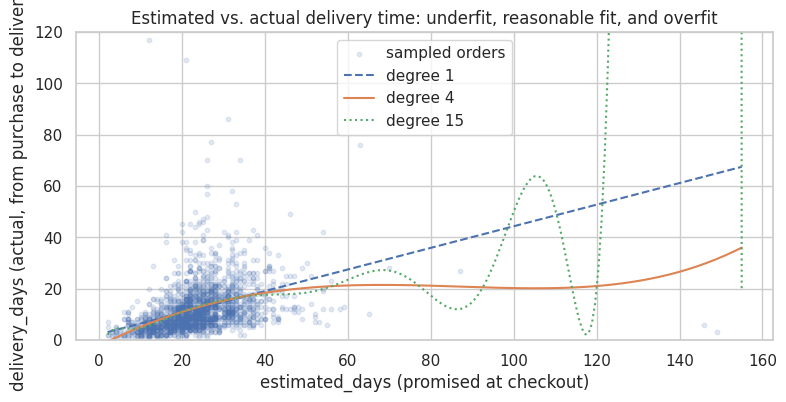

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sample = bv_data.sample(2000, random_state=42)
ax.scatter(sample['estimated_days'], sample['delivery_days'], alpha=0.15, s=10, label='sampled orders')

x_grid = np.linspace(x.min(), x.max(), 200)
for degree, style in zip([1, 4, 15], ['--', '-', ':']):
    coeffs = np.polyfit(x_train, y_train, degree)
    ax.plot(x_grid, np.polyval(coeffs, x_grid), style, label=f'degree {degree}')

ax.set_ylim(0, 120)
ax.set_title('Estimated vs. actual delivery time: underfit, reasonable fit, and overfit')
ax.set_xlabel('estimated_days (promised at checkout)')
ax.set_ylabel('delivery_days (actual, from purchase to delivery)')
ax.legend()
plt.show()
# The degree 15 curve is not fully visible here. It swings far outside this y-axis
# range at the edges of the data, which is exactly the kind of extreme behavior a
# validation set catches before a model like this reaches production.

This is why the train, validation, and test split from Block 2 matters so much. Training error alone cannot tell you whether a model has high variance, because an overfit model looks great on training data by design. You need a validation set the model never trained on to catch it.

Starting in Session 4, every model we fit has settings that move it along this same spectrum: regularization strength for linear models, tree depth for decision trees. The bias and variance tradeoff you just saw in real delivery data is the same tradeoff you will manage in every session from here on.

In [ ]:
# Exercise 5.1
# Add degree=2 to the loop above (or copy the loop and add it).
# Where does its train_mse and val_mse fall relative to degree 1, 4, and 15?
# Would you call it closer to high bias, closer to high variance, or a reasonable middle ground?

# TODO: your code here


#This is just a direct copy paste ofthe above example adding the 4th degree to the variable

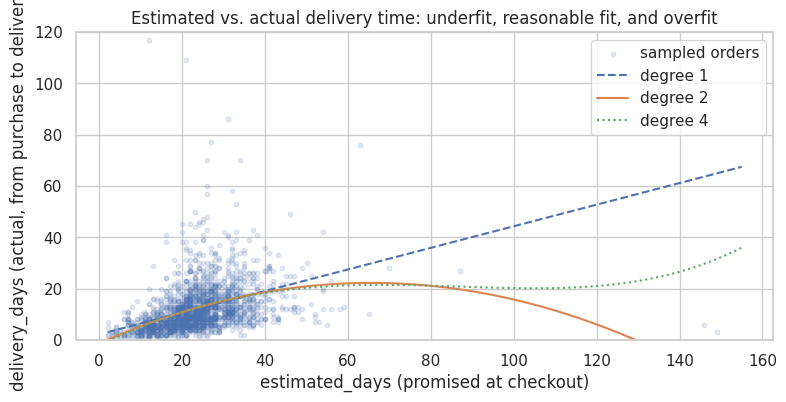

In [ ]:


fig, ax = plt.subplots(figsize=(9, 4))
sample = bv_data.sample(2000, random_state=42)
ax.scatter(sample['estimated_days'], sample['delivery_days'], alpha=0.15, s=10, label='sampled orders')

x_grid = np.linspace(x.min(), x.max(), 200)
for degree, style in zip([1, 2, 4, 15], ['--', '-', ':']):
    coeffs = np.polyfit(x_train, y_train, degree)
    ax.plot(x_grid, np.polyval(coeffs, x_grid), style, label=f'degree {degree}')

ax.set_ylim(0, 120)
ax.set_title('Estimated vs. actual delivery time: underfit, reasonable fit, and overfit')
ax.set_xlabel('estimated_days (promised at checkout)')
ax.set_ylabel('delivery_days (actual, from purchase to delivery)')
ax.legend()
plt.show()

---

## Challenge Block — A New Leakage Trap in Review Timing (Self-Directed Stretch)

> **This block is yours to attempt first.** Kemi walks through it live after about 5 to 7 minutes.

### Context

The Olist dataset has a table you have not used yet, called `olist_order_reviews_dataset.csv`. Each row is one review left by a customer, with a `review_score` and a `review_creation_date`.

Suppose a teammate suggests adding `review_creation_date`, or even `review_score`, as a feature for predicting `is_late`. Your job is to check whether that is safe, using the same question from Block 4. When is this information actually known?

### Your task (attempt before the walkthrough)

1. Load `olist_order_reviews_dataset.csv` and merge it onto `delivered` using `order_id`.
2. Compute the gap in days between `review_creation_date` and `order_delivered_customer_date`.
3. What share of reviews are created on or after the recorded delivery date?
4. Decide: is `review_creation_date` safe to use as a feature for predicting `is_late` at order time? Write your reasoning as a one-line comment.

---

In [ ]:
# Challenge — Step 1: load and merge the reviews table

# TODO: your code here


In [ ]:
# Challenge — Step 2: compute the gap in days between review_creation_date and
# order_delivered_customer_date

# TODO: your code here


In [ ]:
# Challenge — Step 3: what share of reviews come on or after the delivery date?

# TODO: your code here


In [ ]:
# Challenge — Step 4: your decision and reasoning

# TODO: your answer here, as a comment


In [ ]:
# ── WALKTHROUGH (Kemi reveals this live) ──
# Step 1: load and merge
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')

reviewed = delivered.merge(
    reviews[['order_id', 'review_score', 'review_creation_date']],
    on='order_id', how='inner',
)
print(f'Orders with a matching review: {len(reviewed):,} of {len(delivered):,}')

Orders with a matching review: 96,359 of 96,476


In [ ]:
# Steps 2 and 3: the gap between review creation and delivery
reviewed['review_gap_days'] = (
    reviewed['review_creation_date'] - reviewed['order_delivered_customer_date']
).dt.days

on_or_after = (reviewed['review_gap_days'] >= 0).mean()
print(f'Reviews created on or after the delivery date: {on_or_after*100:.1f}%')
print(reviewed['review_gap_days'].describe())

Reviews created on or after the delivery date: 91.4%
count   96359.00
mean       -0.54
std         4.68
min      -187.00
25%         0.00
50%         0.00
75%         0.00
max       106.00
Name: review_gap_days, dtype: float64


### Step 4: the answer

`review_creation_date` is not safe. About 91% of reviews are created on or after the delivery date already recorded for the order, and most of the rest are off by only a day or two. That small remainder is most likely explained by how Olist's review request is triggered around delivery rather than the exact scan timestamp. Either way, a review only exists once an order has reached, or nearly reached, the customer.

The same reasoning applies to `review_score`. A customer writes a review after receiving the order, so the score is shaped by their delivery experience, including whether it was late. Using it to predict lateness would let the model see an effect of the outcome and treat it as a cause.

The pattern to carry forward is this. Any column tied to an event that happens after the order ships, e.g., a customer review, is a leakage risk until you check when it actually gets created.

---

## Wrap — What We Built Today

| Skill | Where we used it |
|-------|-------------------|
| Train, validation, and test split with stratification | Block 2 |
| Majority class baseline for classification | Block 3 |
| Mean and median predictor for regression | Block 3 |
| Spotting data leakage from feature timing | Block 4 |
| Reading bias and variance from train vs validation error | Block 5 |
| Stretch: a leakage check on an unseen table | Challenge Block |

**The takeaway:** every tool from today exists to keep you honest about whether a model actually works. The split protects you from fooling yourself with training performance. The baseline sets the number a fitted model has to beat. The leakage check protects you from a feature that already contains the answer. The bias and variance lens tells you which direction to push a model that is not doing well yet.

---

**Before next class:** finish the exercises you skipped and work through the supplement notebook. Session 4 starts fitting linear and logistic regression models, and shows how regularization controls the exact bias and variance tradeoff from Block 5.